In [54]:
from pyspark.sql import SparkSession
import pyspark.sql.functions as F
from dotenv import load_dotenv
import os 

load_dotenv()

True

In [55]:
spark = (
    SparkSession.builder
    .appName("desafio_09_jdbc")
    .config("spark.jars", "/opt/jdbc/postgresql.jar")
    .getOrCreate()
)



In [56]:
jdbc_url = "jdbc:postgresql://postgres:5432/spark_db"

credencias_banco = {
    "user" : "postgres",
    "password": os.getenv("POSTGRES_PASSWORD"),
    "driver" : "org.postgresql.Driver"
}

Parte A — Leitura JDBC básica

In [57]:
df_read_fato_perdidos_large = spark.read.jdbc(
    url= jdbc_url,
    table= "public.fato_pedidos_large",
    properties= credencias_banco
)

In [58]:
df_read_fato_perdidos_large.count()

2000000

In [59]:
df_read_fato_perdidos_large.rdd.getNumPartitions()

1

In [60]:
df_read_fato_perdidos_large.printSchema()

root
 |-- pedido_id: integer (nullable = true)
 |-- cliente_id: integer (nullable = true)
 |-- data_pedido: date (nullable = true)
 |-- status: string (nullable = true)
 |-- canal: string (nullable = true)
 |-- valor_total: decimal(38,18) (nullable = true)



Explique por que uma leitura JDBC simples pode ser um gargalo mesmo quando estamos usando Spark.

Resposta: Nesse cenario não estamos extraindo o que o Spark tem de melhor, como temos um bancos de dados com 2 milhoes de linhas, ler tudo isso utilizando apenas uma partição tende a ser muito mais lento do que dividir o trabalho em mais de uma partição, por fim, nessa circustancia, perdemos pararelismo que seria gerada a partir da criação de mais partições

Parte B — Descobrindo os bounds

COUNT(*)
→ responde o quê?

MIN/MAX
→ respondem o quê?

qual deles deve orientar lowerBound/upperBound?

Resposta: COUNT(*) responde quantas linhas aquele tabela possui, MIN/MAX representa o valor minimo e o valor maximo de uma coluna, por exemplo podemos descobrir o valor minimo de cliente_id e o valor maximo tambem, sobre lower/upper Bound, nos orientamos com o MIN para o valor minimo(lower bound) e MAX para o valor maximo(upperbound), dessa forma a partir dos bounds o spark consegue ter uma orientação dos  cortes na faixa de valores da coluna, porem pode haver uma variação na divisão de registros entre partições. 

Parte C — Leitura JDBC paralela

In [61]:
df_leitura_paralela = spark.read.jdbc(
    url= jdbc_url,
    properties= credencias_banco,
    table= "public.fato_pedidos_large",
    column= "pedido_id",
    lowerBound= 1,
    upperBound= 2000000,
    numPartitions= 4 
)

In [62]:
df_leitura_paralela.rdd.getNumPartitions()

4

In [63]:
df_read_fato_perdidos_large.rdd.getNumPartitions()

1

In [64]:
df_leitura_paralela.count()

2000000

In [65]:
df_read_fato_perdidos_large.count()

2000000

In [66]:
(
    df_leitura_paralela.withColumn("quantidade_particoes", F.spark_partition_id())
    .groupBy("quantidade_particoes")
    .count()
    .orderBy("quantidade_particoes")
).show()

+--------------------+------+
|quantidade_particoes| count|
+--------------------+------+
|                   0|500001|
|                   1|499999|
|                   2|499999|
|                   3|500001|
+--------------------+------+



Explique se a distribuição ficou equilibrada e por que pedido_id funcionou bem como partitionColumn neste dataset.

Resposta: A distribuiçãi ficou praticamente perfeita, das 4 partições 2 ficaram com 500001 linhas e as outras 2 com 499999, pedido_id ficou ideal como partitionColumn pois alem de ser uma coluna numericas, e geralmente colunas como essas são sequenciais, chaves primeiras e distintas, elas acabam garantindo uma distribuição de dados uniforme e eficiente entre partições. 

Parte D — O erro proposital dos bounds

In [67]:
df_leitura_paralela2 = spark.read.jdbc(
    url= jdbc_url,
    properties= credencias_banco,
    table= "public.fato_pedidos_large",
    column= "pedido_id",
    lowerBound= 1,
    upperBound= 500000,
    numPartitions = 4
)

In [68]:
(
    df_leitura_paralela2.withColumn("quantidade_particoes", F.spark_partition_id())
    .groupBy("quantidade_particoes")
    .count()
    .orderBy("quantidade_particoes")
).show()

+--------------------+-------+
|quantidade_particoes|  count|
+--------------------+-------+
|                   0| 125000|
|                   1| 124999|
|                   2| 124999|
|                   3|1625002|
+--------------------+-------+



Por que upperBound=500000 não significa que o Spark vai ler apenas registros com pedido_id <= 500000?

Resposta: upperBound=500000 não significa que o Spark vai ler apenas registros com pedido_id <= 500000, pois o spark não ignora necessariamente as outras 1,5M de linhas presentes no banco de dados, então mesmo definindo o upperBound com 1/4 das linhas, o spark ainda sim continuara lendo o restante, e partir disso haverá uma desbalanceamento dos dados entre partições.


Parte E — Filtrar antes de atravessar JDBC

In [69]:
df_status = spark.read.jdbc(
    url= jdbc_url,
    properties= credencias_banco,
    table= """(
        
        SELECT
            pedido_id,
            cliente_id,
            valor_total
        FROM public.fato_pedidos_large 
        WHERE status = 'concluido'
        
    )AS df_status_concluido""",
    column= "pedido_id",
    lowerBound= 1,
    upperBound= 2000000,
    numPartitions = 4
)

In [70]:
df_status.count()

500000

In [71]:
(
    df_status.withColumn("quantidade_particoes", F.spark_partition_id())
    .groupBy("quantidade_particoes")
    .count()
    .orderBy("quantidade_particoes")
    
).show()

+--------------------+------+
|quantidade_particoes| count|
+--------------------+------+
|                   0|125000|
|                   1|125000|
|                   2|124999|
|                   3|125001|
+--------------------+------+



Explique por que 500 mil linhas retornadas não significa que upperBound = 500 mil

Resposta: 500K de linhas retornadas não significa upperbound = 500k, pois nesse cenario estamos realizando um filtro entao como o spark não ignora o restante das linhas no banco de dados haverá um desbalanceamento entre as partições, num contexto com 4 partições, a ultima partição acumulará a maioria dos dados, então é importante diferenciar quantidade de linhas x faixa de valores da partitionColumn, não por que o df especificamente possuiu 500 mil linhas que utilizaremos ela como faixa de valor para o upperBound, sendo que no banco de dados há muito mais linhas e com isso havera um desbalanceamento na ultima partição.

Parte F — fetchsize

In [72]:
df_fetchsize = spark.read.jdbc(
    url= jdbc_url,
    properties= {**credencias_banco, "fetchsize" : "1000"},
    table= "public.fato_pedidos_large",
    column= "pedido_id",
    lowerBound= 1,
    upperBound= 2000000,
    numPartitions= 4
)

In [73]:
df_fetchsize.rdd.getNumPartitions()

4

Explique por que alterar fetchsize não deve alterar as quatro Spark Partitions.

Resposta: Nesse cenario é importante diferenciar paralelismo x leitura de lote, a letiura de lote com fetchsize não altera as quatro partições pois o objetivo dela é fazer com que cada partição leia uma determinada quantidade de dados, então cada grupo particionado ira ler 1000 dados por sequencias, ate fechar os 2 milhoes do banco, não afetando o paralelismo e otimizando o processamento do spark. 

Parte G — Escrita para PostgreSQL

In [75]:
df_status.write.jdbc(
   url= jdbc_url,
   mode= "overwrite",
   table= "public.desafio_pedidos_concluidos",
   properties= {**credencias_banco, "batchsize": "5000" }
)

In [76]:
df_status.write.jdbc(
   url= jdbc_url,
   mode= "append",
   table= "public.desafio_pedidos_concluidos",
   properties= {**credencias_banco, "batchsize" : "5000" }
)

confira a contagem com append.
Explique por que ela dobrou.

Resposta: O registros do banco dobraram apos a utilização do metodo append, pois uma nova carga foi feita sem alterar o que ja estava escrito no banco de dados, como haviam 500K linhas originais apos rodar a escrita de novo com o metodo append foram escritas novamente mais 500K linhas, totalizando 1M de linhas.

Depois responda:
O append oferece proteção automática contra registros duplicados?

Resposta: Não oferece, se ja existem dados duplicados na primeira escrita, apos realizar uma nova escrita com o append, esses dados continuarão duplicados, a função do append é apenas escrever os dados no banco sem apagar aqueles que ja estão lá

Parte H — Validação de tipos

In [51]:
df_status.printSchema()

root
 |-- pedido_id: integer (nullable = true)
 |-- cliente_id: integer (nullable = true)
 |-- valor_total: decimal(38,18) (nullable = true)



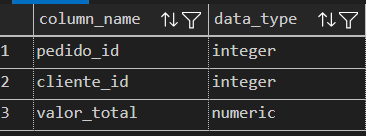

A titulo de comparação entre jdbc x postgresSQL, temos: 
IntegerType ↔ integer
StringType  ↔ text
DecimalType ↔ numeric



In [52]:
spark.stop()

Questão final da Aula 09
Imagine uma tabela PostgreSQL com 300 milhões de registros.
O pipeline precisa apenas de registros dos últimos dias e somente quatro colunas.
Você dispõe de Spark com vários executores.
Explique por que esta abordagem seria ruim:
PostgreSQL
↓
300 milhões de linhas completas
↓
1 partição JDBC
↓
Spark
↓
filter/select

e descreva uma abordagem melhor considerando:
filtro na origem
seleção das colunas necessárias
partitionColumn
lowerBound / upperBound
numPartitions
fetchsize
pressão sobre o PostgreSQL

Não quero uma configuração numérica “perfeita”; quero ver seu raciocínio de Engenharia de Dados.

Resposta: Essa primeira abordagem torna-se inviavel em multiplos aspectos, uma vez que, queremos selecionar uma quantidade especifica de colunas de um banco de dados para o spark, não faz-se necessario enviar todas as 300M de linhas e todas as colunas para o destinatario, utilizar 1 partição também não serial o ideal, aqui estariamos limitando o poder de processamento do spark e sobrecarregando o mesmo, o melhor a se fazer seria, durante o processo de leitura, utilizar uma subquery selecionando apenas as colunas necessarias, definir um numero de partições para o spark utilizar, dessa forma otimizando e aumentando a velocidade do processamento, determinaria tambem uma coluna base para os para os parametros determinantes de leitura de faixa de linhas, coluna essa que poderia ser uma chave primeira, ja que ela costuma ser incremental, distinta e numerica, seria interessante utilizar tambem upper e lower bound, com esses dois metodos podemos definir a faixa de dados que o spark processara em cada partição, tornando algo mais equilibrado e por fim utilizar o metodo fetchsize tambem seria uma boa pratica, visto que, cada partição processara uma determinada quantidade de dados por vez, por exemplo, caso definissimos fetchsize = 1000, cada partição ira processar 1000 dados por vez. 